## IMPORT LIBRARY


In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [2]:
data = pd.read_excel("indeks-standar-pencemaran-udara-(ispu)-tahun-2017-komponen-data.xlsx")

data

,periode_data,tanggal,stasiun,pm10,so2,co,o3,no2,max,critical,categori
0,201701,2017-01-27,DKI5 (KEBON JERUK),5,11,29,37,14,37,O3,BAIK
1,201701,2017-01-28,DKI5 (KEBON JERUK),5,11,28,42,6,42,O3,BAIK
2,201701,2017-01-29,DKI5 (KEBON JERUK),6,11,29,26,13,29,CO,BAIK
3,201701,2017-01-30,DKI5 (KEBON JERUK),7,11,28,41,5,41,O3,BAIK
4,201701,2017-01-31,DKI5 (KEBON JERUK),6,11,26,42,7,42,O3,BAIK
...,...,...,...,...,...,...,...,...,...,...,...
1820,201712,2017-12-27,DKI5 (KEBON JERUK),21,21,26,30,4,30,O3,BAIK
1821,201712,2017-12-28,DKI5 (KEBON JERUK),29,23,26,46,5,46,O3,BAIK
1822,201712,2017-12-29,DKI5 (KEBON JERUK),55,28,38,47,10,55,PM10,SEDANG
1823,201712,2017-12-30,DKI5 (KEBON JERUK),51,26,31,49,8,51,PM10,SEDANG


## EDA

In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1825 entries, 0 to 1824
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   periode_data  1825 non-null   int64         
 1   tanggal       1825 non-null   datetime64[ns]
 2   stasiun       1825 non-null   object        
 3   pm10          1825 non-null   object        
 4   so2           1825 non-null   object        
 5   co            1825 non-null   object        
 6   o3            1825 non-null   object        
 7   no2           1825 non-null   object        
 8   max           1825 non-null   object        
 9   critical      1800 non-null   object        
 10  categori      1825 non-null   object        
dtypes: datetime64[ns](1), int64(1), object(9)
memory usage: 157.0+ KB


In [4]:
data.shape

(1825, 11)

In [5]:
data.describe()

,periode_data
count,1825.000000
mean,201706.526027
std,3.448796
min,201701.000000
25%,201704.000000
50%,201707.000000
75%,201710.000000
max,201712.000000


In [6]:
data['categori'].unique()

array(['BAIK', 'SEDANG', 'TIDAK ADA DATA', 'TIDAK SEHAT'], dtype=object)

In [7]:
data['categori'].value_counts()

SEDANG            1121
BAIK               476
TIDAK SEHAT        198
TIDAK ADA DATA      30
Name: categori, dtype: int64

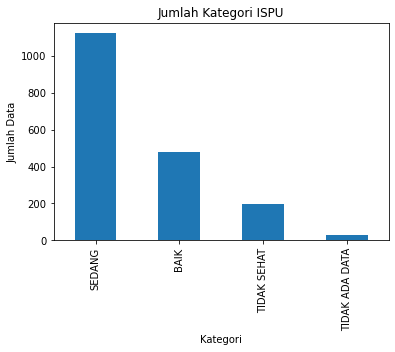

In [8]:
data['categori'].value_counts().plot(kind='bar')

plt.title('Jumlah Kategori ISPU')
plt.xlabel('Kategori')
plt.ylabel('Jumlah Data')
plt.show()

In [9]:
df = data.head(101).copy()

df

,periode_data,tanggal,stasiun,pm10,so2,co,o3,no2,max,critical,categori
0,201701,2017-01-27,DKI5 (KEBON JERUK),5,11,29,37,14,37,O3,BAIK
1,201701,2017-01-28,DKI5 (KEBON JERUK),5,11,28,42,6,42,O3,BAIK
2,201701,2017-01-29,DKI5 (KEBON JERUK),6,11,29,26,13,29,CO,BAIK
3,201701,2017-01-30,DKI5 (KEBON JERUK),7,11,28,41,5,41,O3,BAIK
4,201701,2017-01-31,DKI5 (KEBON JERUK),6,11,26,42,7,42,O3,BAIK
...,...,...,...,...,...,...,...,...,...,...,...
96,201702,2017-02-09,DKI3 (JAGAKARSA),23,31,6,28,3,31,SO2,BAIK
97,201702,2017-02-10,DKI3 (JAGAKARSA),16,31,5,40,3,40,O3,BAIK
98,201702,2017-02-11,DKI3 (JAGAKARSA),27,31,8,45,4,45,O3,BAIK
99,201701,2017-01-01,DKI1 (BUNDERAN HI),63,34,25,21,2,63,PM10,SEDANG


In [10]:
fitur = ['pm10', 'so2', 'co', 'o3', 'no2']

In [11]:
from sklearn.impute import SimpleImputer

df[fitur] = df[fitur].replace('---', np.nan)

# Mengubah tipe data menjadi numerik
df[fitur] = df[fitur].apply(pd.to_numeric, errors='coerce')

# Mengisi missing value menggunakan median
imputer = SimpleImputer(strategy='median')
df[fitur] = imputer.fit_transform(df[fitur])

# Mengecek missing value
print("Missing Value Setelah Penanganan:")
print(df[fitur].isnull().sum())

for kolom in fitur:
    df[kolom] = pd.to_numeric(df[kolom], errors='coerce')

df[fitur].isnull().sum()

Missing Value Setelah Penanganan:
pm10    0
so2     0
co      0
o3      0
no2     0
dtype: int64


pm10    0
so2     0
co      0
o3      0
no2     0
dtype: int64

In [12]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['categori'] = le.fit_transform(df['categori'])

df

,periode_data,tanggal,stasiun,pm10,so2,co,o3,no2,max,critical,categori
0,201701,2017-01-27,DKI5 (KEBON JERUK),5.0,11.0,29.0,37.0,14.0,37,O3,0
1,201701,2017-01-28,DKI5 (KEBON JERUK),5.0,11.0,28.0,42.0,6.0,42,O3,0
2,201701,2017-01-29,DKI5 (KEBON JERUK),6.0,11.0,29.0,26.0,13.0,29,CO,0
3,201701,2017-01-30,DKI5 (KEBON JERUK),7.0,11.0,28.0,41.0,5.0,41,O3,0
4,201701,2017-01-31,DKI5 (KEBON JERUK),6.0,11.0,26.0,42.0,7.0,42,O3,0
...,...,...,...,...,...,...,...,...,...,...,...
96,201702,2017-02-09,DKI3 (JAGAKARSA),23.0,31.0,6.0,28.0,3.0,31,SO2,0
97,201702,2017-02-10,DKI3 (JAGAKARSA),16.0,31.0,5.0,40.0,3.0,40,O3,0
98,201702,2017-02-11,DKI3 (JAGAKARSA),27.0,31.0,8.0,45.0,4.0,45,O3,0
99,201701,2017-01-01,DKI1 (BUNDERAN HI),63.0,34.0,25.0,21.0,2.0,63,PM10,1


In [13]:
x = df[fitur]
x

,pm10,so2,co,o3,no2
0,5.0,11.0,29.0,37.0,14.0
1,5.0,11.0,28.0,42.0,6.0
2,6.0,11.0,29.0,26.0,13.0
3,7.0,11.0,28.0,41.0,5.0
4,6.0,11.0,26.0,42.0,7.0
...,...,...,...,...,...
96,23.0,31.0,6.0,28.0,3.0
97,16.0,31.0,5.0,40.0,3.0
98,27.0,31.0,8.0,45.0,4.0
99,63.0,34.0,25.0,21.0,2.0


In [14]:
y = df['categori']
y

0      0
1      0
2      0
3      0
4      0
      ..
96     0
97     0
98     0
99     1
100    0
Name: categori, Length: 101, dtype: int32

In [15]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.25, random_state=0
)

In [16]:
Q1 = x_train.quantile(0.25)
Q3 = x_train.quantile(0.75)

IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

x_train = x_train.clip(lower=batas_bawah, upper=batas_atas, axis=1)
x_test = x_test.clip(lower=batas_bawah, upper=batas_atas, axis=1)

In [17]:
print("Data Training:", x_train.shape)
print("Data Testing:", x_test.shape)

Data Training: (75, 5)
Data Testing: (26, 5)


## DECISION TREE

In [18]:
from sklearn.tree import DecisionTreeClassifier

classifier = DecisionTreeClassifier()
classifier.fit(x_train, y_train)

DecisionTreeClassifier()

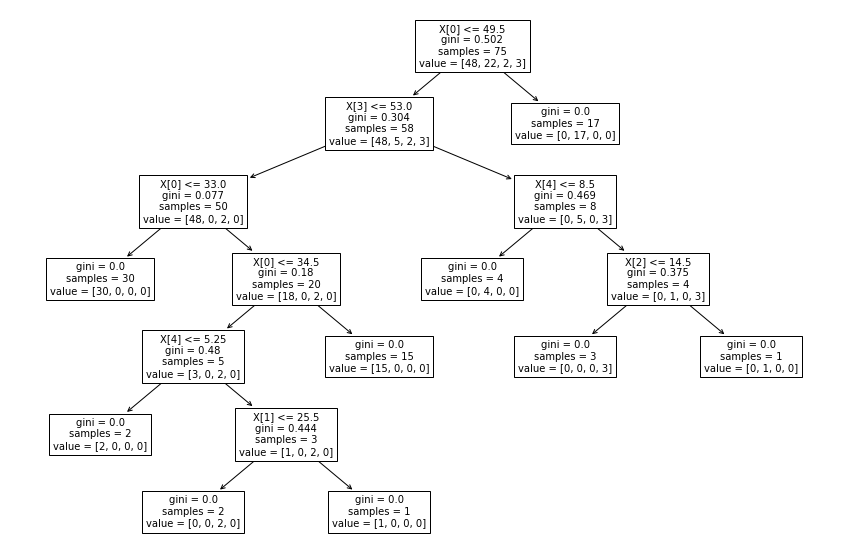

In [19]:
from sklearn import tree

plt.subplots(figsize = (15,10))
tree.plot_tree(classifier, fontsize = 10)
plt.show()

In [20]:
from sklearn.metrics import accuracy_score

y_pred = classifier.predict(x_test)

accuracy = accuracy_score(y_test, y_pred)

print("Akurasi:", accuracy)

Akurasi: 0.8846153846153846


In [21]:
df_baru = pd.DataFrame(
    [[45, 20, 15, 60, 8]],
    columns=fitur
)

df_baru = df_baru.clip(
    lower=batas_bawah,
    upper=batas_atas,
    axis=1
)

prediksi = classifier.predict(imputer.transform(df_baru))

print("Hasil Prediksi:", le.inverse_transform(prediksi))

Hasil Prediksi: ['SEDANG']


In [22]:
print("Distribusi data training:")
print(pd.Series(y_train).value_counts())

Distribusi data training:
0    48
1    22
3     3
2     2
Name: categori, dtype: int64
